In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, f1_score, classification_report
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv")
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [3]:
df.shape

(569, 33)

In [4]:
df.dtypes

id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst     

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [6]:
df.isnull().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [7]:
df = df.drop(columns= ["id","Unnamed: 32"])

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [10]:
df["diagnosis"].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

<Axes: xlabel='diagnosis'>

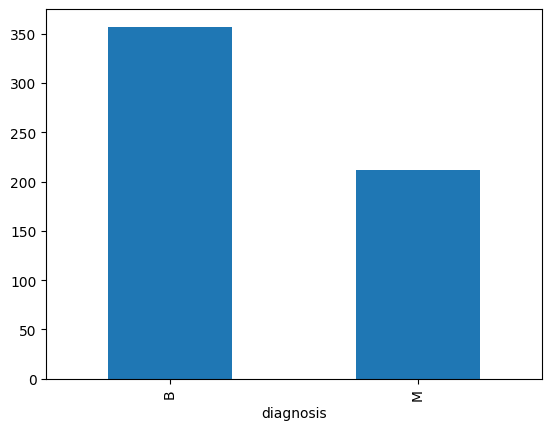

In [11]:
df["diagnosis"].value_counts().plot(kind= "bar")

In [12]:
df["diagnosis"] = df["diagnosis"].map({
     "B" : 0,
     "M" : 1
})

In [13]:
x = df.drop(columns= ["diagnosis"])
y = df["diagnosis"]

In [14]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state= 42)

In [15]:
smote = SMOTE(random_state = 42)
x_train_smote, y_train_smote = smote.fit_resample(
    x_train,
    y_train
)


In [16]:
model = DecisionTreeClassifier(
    max_depth = 5,
    random_state = 42
)

In [17]:
model.fit(x_train_smote, y_train_smote)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [18]:
predictions_test = model.predict(x_test)

In [19]:
predictions_train = model.predict(x_train_smote)

In [20]:
train_accuracy = accuracy_score(y_train_smote, predictions_train)
test_accuracy = accuracy_score(y_test, predictions_test)

In [21]:
print("Train Accuracy: ", train_accuracy)
print("Test Accuracy: ", test_accuracy)

Train Accuracy:  0.9912587412587412
Test Accuracy:  0.956140350877193


In [22]:
print(classification_report(
    y_test,
    predictions_test,
    target_names=["B", "M"],
    zero_division=0
))

              precision    recall  f1-score   support

           B       0.96      0.97      0.97        71
           M       0.95      0.93      0.94        43

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



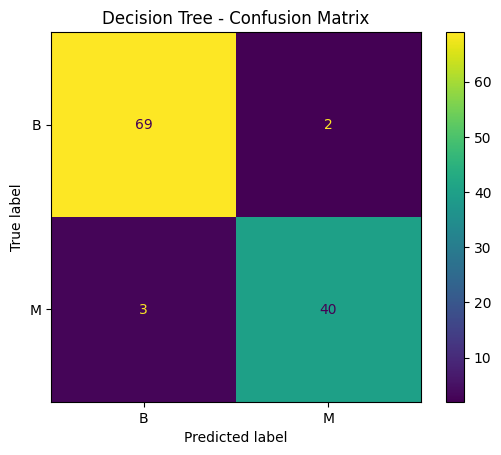

In [23]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions_test,
    display_labels=["B", "M"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()

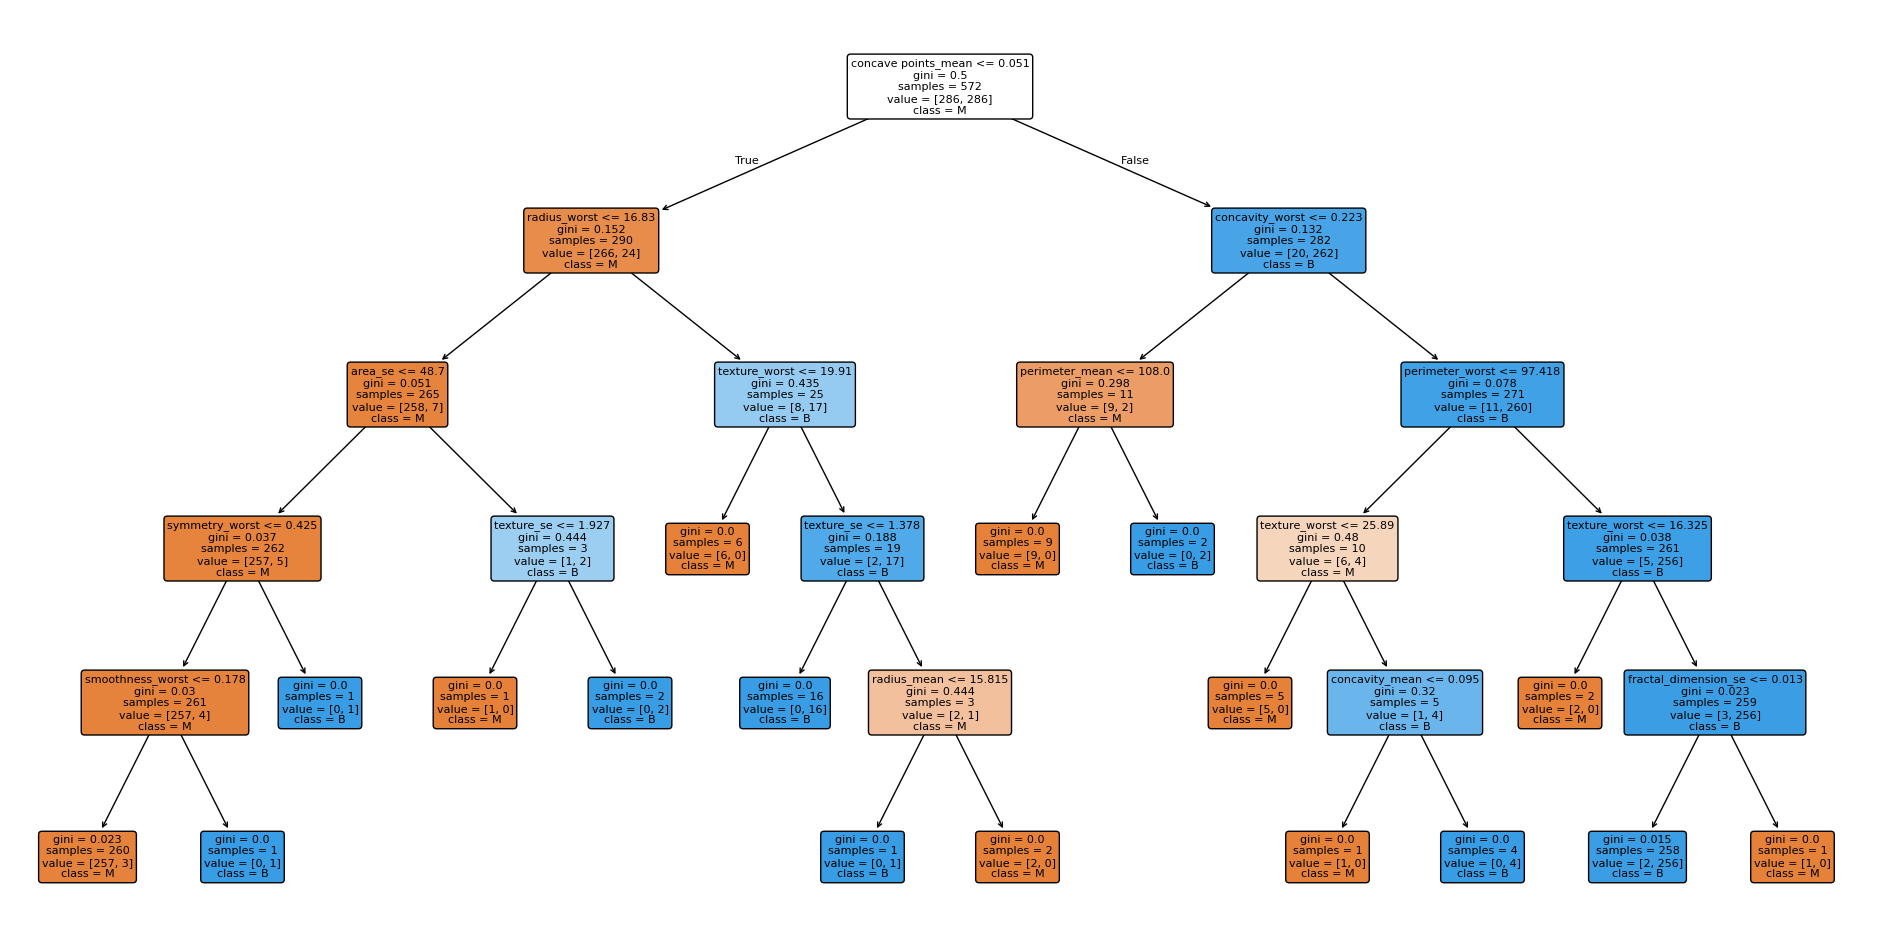

In [24]:
plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=x_train.columns,
    class_names=["M", "B"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()

In [25]:
importance = pd.DataFrame({
    "Feature": x_train.columns,
    "Importance" : model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(10)

,Feature,Importance
7,concave points_mean,0.741793
20,radius_worst,0.070690
21,texture_worst,0.052079
26,concavity_worst,0.046300
22,perimeter_worst,0.023537
11,texture_se,0.012962
2,perimeter_mean,0.011853
13,area_se,0.009010
19,fractal_dimension_se,0.007104
24,smoothness_worst,0.007050


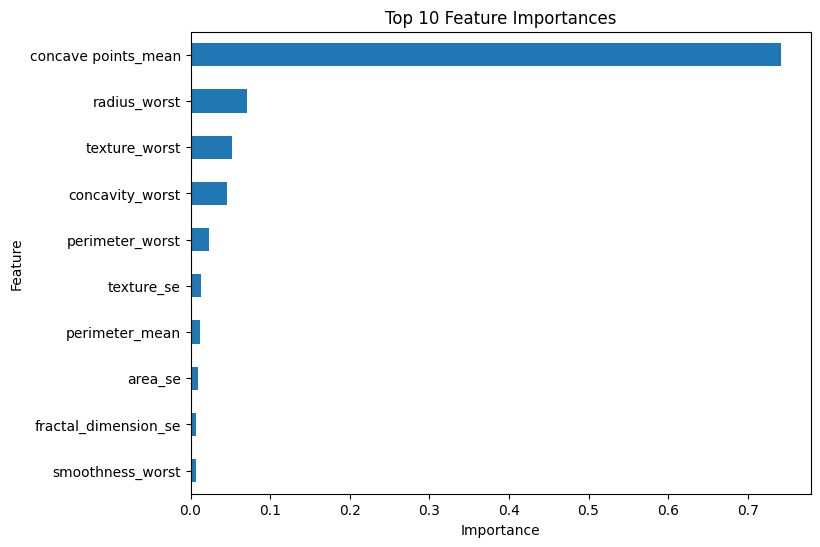

In [26]:
importance.head(10).sort_values(
    by="Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(8, 6)
)

plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()


## تجربة الـ Model على Data جديدة

بعد ما درّبنا الـ Decision Tree وقيّمنا أداءه، نقدر دلوقتي نستخدمه على Data جديدة ماشفهاش قبل كده.

الـ Model مش محتاج يعرف الـ diagnosis الحقيقي.
هو بياخد نفس الـ Features اللي اتدرّب عليها، وبعد كده يعمل Prediction للـ Class.

لازم الـ New Data تحتوي على نفس الـ Features اللي استخدمناها وقت الـ Training.

### إدخال القيم يدويًا

بدل ما نكتب كل القيم داخل الكود، ممكن نخلي المستخدم يدخل قيمة لكل Feature بنفسه.

- `x_train.columns` فيها أسماء الـ Features اللي استخدمناها في الـ Training.
- الـ `for loop` بتمر على كل Feature واحدة واحدة.
- `input()` بتاخد القيمة من المستخدم.
- `float()` بتحول القيمة لرقم.
- بنخزن القيم داخل Dictionary اسمها `new_values`.
- في الآخر بنحول الـ Dictionary إلى `DataFrame` لأن الـ Model بيستقبل الـ Data في شكل جدول.

### إنشاء Sample جديدة

في المثال ده هنكتب قيم الـ Features مباشرة داخل الكود.

كل اسم يمثل Feature، والقيمة اللي قدامه تمثل قيمة الـ Feature للحالة الجديدة.

بعد كده نستخدم `pd.DataFrame()` علشان نحول القيم إلى صف واحد داخل جدول.

الصف ده بيمثل حالة جديدة والـ Model هيحاول يصنفها.

In [27]:
# new_values = {}

# for feature in x_train.columns:
#     value = float(input(f"Enter {feature}: "))
#     new_values[feature] = value

# new_data = pd.DataFrame([new_values])

# new_data

new_data = pd.DataFrame([{
    "radius_mean": 17.99,
    "texture_mean": 10.38,
    "perimeter_mean": 122.80,
    "area_mean": 1001.0,
    "smoothness_mean": 0.11840,
    "compactness_mean": 0.27760,
    "concavity_mean": 0.30010,
    "concave points_mean": 0.14710,
    "symmetry_mean": 0.2419,
    "fractal_dimension_mean": 0.07871,

    "radius_se": 1.095,
    "texture_se": 0.9053,
    "perimeter_se": 8.589,
    "area_se": 153.4,
    "smoothness_se": 0.006399,
    "compactness_se": 0.04904,
    "concavity_se": 0.05373,
    "concave points_se": 0.01587,
    "symmetry_se": 0.03003,
    "fractal_dimension_se": 0.006193,

    "radius_worst": 25.38,
    "texture_worst": 17.33,
    "perimeter_worst": 184.60,
    "area_worst": 2019.0,
    "smoothness_worst": 0.16220,
    "compactness_worst": 0.66560,
    "concavity_worst": 0.7119,
    "concave points_worst": 0.2654,
    "symmetry_worst": 0.4601,
    "fractal_dimension_worst": 0.11890
}])

new_data

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.8,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189


> **ملاحظة:** لازم أسماء وترتيب الـ Features في الـ New Data يكونوا متوافقين مع الـ Features اللي اتدرب عليها الـ Model.

## عمل Prediction

دلوقتي هنرسل الـ New Data للـ Model المتدرب.

الدالة `predict()` بتخلي الـ Model يتوقع الـ Class للحالة الجديدة.

في الـ Target Encoding عندنا:

- `0` = Benign (B)
- `1` = Malignant (M)

ولأننا بنجرب على Sample واحدة فقط، نستخدم `prediction[0]` علشان نجيب النتيجة الخاصة بيها.

الـ Model استخدم الـ Patterns اللي اتعلمها أثناء الـ Training علشان يعمل Prediction للحالة الجديدة.

لاحظ إننا ماعملناش Training مرة تانية.

`fit()` بنستخدمها في الـ Training، أما `predict()` بنستخدمها بعد ما الـ Model يكون اتدرب بالفعل.ر

In [28]:
prediction = model.predict(new_data)

if prediction[0] == 0:
    print("Prediction: Benign (B)")
else:
    print("Prediction: Malignant (M)")

Prediction: Malignant (M)


## حفظ الـ Trained Model

بعد ما ندرب الـ Model، مش منطقي نعيد الـ Training كل مرة نحتاج نستخدمه فيها.

علشان كده نقدر نحفظ الـ Trained Model داخل File.

هنستخدم مكتبة `joblib`.

الدالة `joblib.dump()` بتحفظ الـ Model بعد الـ Training علشان نقدر نستخدمه بعدين بدون ما نعمل `fit()` من جديد.

In [29]:
import joblib

joblib.dump(model, "breast_cancer_decision_tree.pkl")

print("Model saved successfully!")

Model saved successfully!


## تحميل الـ Saved Model

بعد ما نحفظ الـ Model، نقدر نحمله مرة تانية باستخدام `joblib.load()`.

الـ Loaded Model بيكون محتفظ باللي اتعلمه أثناء الـ Training.

علشان كده نقدر نستخدمه مباشرة في `predict()` بدون ما نعمل Training من جديد.

In [30]:
import joblib

loaded_model = joblib.load(
    "breast_cancer_decision_tree.pkl"
)

print("Model loaded successfully!")

Model loaded successfully!


### استخدام الـ Loaded Model

دلوقتي نقدر نستخدم الـ Loaded Model بنفس طريقة الـ Model الأصلي.

هنديله New Data ونستخدم `predict()` علشان يطلع النتيجة.

In [31]:
prediction = loaded_model.predict(new_data)

if prediction[0] == 0:
    print("Prediction: Benign (B)")
else:
    print("Prediction: Malignant (M)")

Prediction: Malignant (M)


## Summary

في الجزء ده اتعلمنا إزاي:

1. ندخل Data جديدة للـ Model.
2. نستخدم `predict()` علشان نعمل Prediction.
3. نفرق بين `fit()` و `predict()`.
4. نحفظ الـ Model باستخدام `joblib.dump()`.
5. نحمل الـ Model باستخدام `joblib.load()`.
6. نستخدم الـ Model مرة تانية بدون إعادة الـ Training.

### Workflow

Training Data  
↓  
`fit()`  
↓  
Trained Model  
↓  
Save Model  
↓  
Load Model  
↓  
New Data  
↓  
`predict()`  
↓  
Prediction